In [2]:
import sys
sys.path.append("..")

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

from src.data import get_data
from src.evaluate import log_result, metrics, plot_results, show
from src.preprocess import build_pipeline, light_stem, stem
from src.train import fit_with_threshold, set_seed

set_seed(42)

c:\Users\rawi9\Desktop\BDIO\LLM\tps\tp2-arabic-sarcasm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
train, val, test, report = get_data()
for k, v in report.items():
    print(f"{k}: {v}")

start: 11293
in_test: 17
in_val: 82
conflicting: 102
duplicates: 311
end: 10781


In [ ]:
def build_model(C=1.0):
    
    words = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    chars = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
    
    return make_pipeline(
        make_union(words, chars),
        LogisticRegression(class_weight="balanced", max_iter=1000)
        )

In [ ]:
def run(combos):
    rows = []
    for name, steps in combos.items():
        prep = build_pipeline(steps)
        X_train, X_val = train["tweet"].apply(prep), val["tweet"].apply(prep)

        model = build_model()
        threshold, seconds = fit_with_threshold(model, X_train, train["sarcasm"], X_val, val["sarcasm"])
        scores = metrics(val["sarcasm"], model.predict_proba(X_val)[:, 1], threshold)

        log_result(
            model="tfidf_lr",
            preprocessing=name,
            seed=42,
            threshold=threshold,
            train_time=seconds,
            trained_params=model[-1].coef_.size + 1,
            **{f"val_{k}": v for k, v in scores.items()}
        )
        
        show(name, scores, threshold, seconds)
        rows.append({"preprocessing": name, "threshold": threshold, **scores})

    return pd.DataFrame(rows).set_index("preprocessing")

In [6]:
BASE = ["html","mentions", "hashtags"]
EMOJI = ["emoji"]
NORM = ["diacritics", "kashida", "letters", "elongation"]
LIGHT = ["light_stem"]

COMBOS = {
    "base":                      BASE,
    "emoji":                     BASE + EMOJI,
    "norm":                      BASE + NORM,
    "light_stem":                BASE + LIGHT,
    "emoji + norm":              BASE + EMOJI + NORM,
    "emoji + light_stem":        BASE + EMOJI + LIGHT,
    "norm + light_stem":         BASE + NORM + LIGHT,
    "emoji + norm + light_stem": BASE + EMOJI + NORM + LIGHT,
    "urls kept":                 ["html", "mentions", "hashtags"],
}

table = run(COMBOS)

base                         f1=0.5105  pr_auc=0.5180  threshold=0.44  4s
emoji                        f1=0.5308  pr_auc=0.5326  threshold=0.47  5s
norm                         f1=0.5221  pr_auc=0.5140  threshold=0.51  4s
light_stem                   f1=0.5380  pr_auc=0.5042  threshold=0.46  3s
emoji + norm                 f1=0.5369  pr_auc=0.5279  threshold=0.53  3s
emoji + light_stem           f1=0.5455  pr_auc=0.5138  threshold=0.50  3s
norm + light_stem            f1=0.5465  pr_auc=0.5200  threshold=0.49  3s
emoji + norm + light_stem    f1=0.5533  pr_auc=0.5312  threshold=0.52  2s
urls kept                    f1=0.5105  pr_auc=0.5180  threshold=0.44  3s


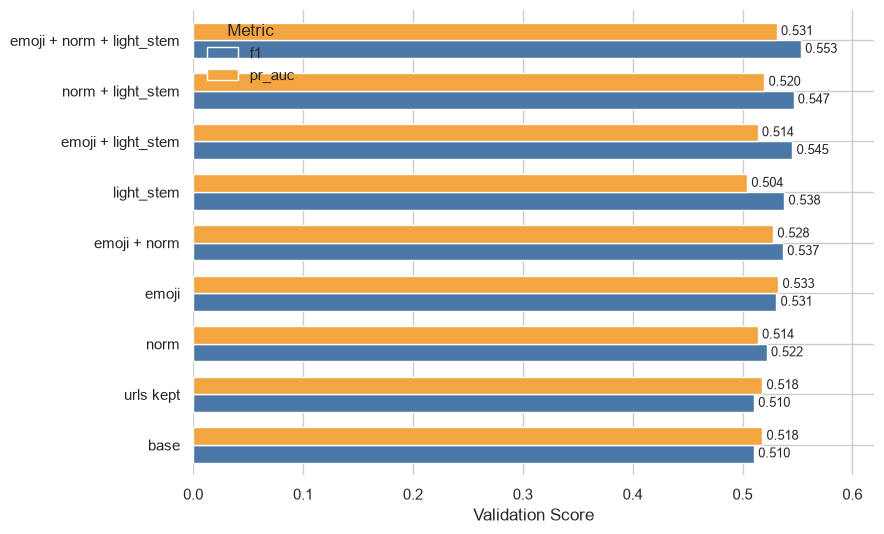

In [7]:
plot_results(table)